# Notebook 06: Statistical Baseline Imputation

This notebook implements statistical baseline methods for PM2.5 imputation.

Notebook 05 created the modelling-ready datasets and artificial masking scenarios. The masked datasets preserve the original PM2.5 values in `PM25_original` and provide the model-visible input column as `PM25_model_input`.

The main purpose of this notebook is to evaluate simple and interpretable statistical imputation baselines before moving to machine-learning and deep-learning models.

The first baseline methods are:

1. Station-level train mean imputation
2. Linear interpolation

Later sections will extend the statistical baseline stage with Kalman / ARIMA-style models, AIC-based candidate selection and residual diagnostics.

Important leakage rule:

`PM25_original` must only be used for evaluation.  
Model inputs and imputation methods must use `PM25_model_input`.

In [1]:
# ============================================================
# Notebook 06: Statistical Baseline Imputation
# Step 1: Setup and file paths
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from time import perf_counter

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 140)

# Main project root.
PROJECT_ROOT = Path.home() / "Desktop" / "DISSERTATION" / "Codes"

# Data folders.
DATA_ROOT = PROJECT_ROOT / "data"
MODELLING_DIR = DATA_ROOT / "modelling"

# Output folders.
RESULTS_ROOT = PROJECT_ROOT / "results"
MODELS_ROOT = PROJECT_ROOT / "models"

# Notebook-specific output folders.
RESULTS_DIR = RESULTS_ROOT / "statistical_baselines"
STAT_MODELS_DIR = MODELS_ROOT / "statistical_baselines"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
STAT_MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Final masking scenario summary created in Notebook 05.
scenario_manifest_path = MODELLING_DIR / "final_masking_scenario_summary.csv"

print("Project root:", PROJECT_ROOT)
print("Modelling input directory:", MODELLING_DIR)
print("Results output directory:", RESULTS_DIR)
print("Statistical model artefact directory:", STAT_MODELS_DIR)
print("Scenario manifest path:", scenario_manifest_path)

Project root: C:\Users\Msi\Desktop\DISSERTATION\Codes
Modelling input directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling
Results output directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines
Statistical model artefact directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\models\statistical_baselines
Scenario manifest path: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling\final_masking_scenario_summary.csv


## Step 2: Load the final masking scenario manifest

Notebook 05 created five artificial masking scenarios:

- `random10_point`
- `random30_point`
- `random50_point`
- `block24_10percent`
- `block72_10percent`

The manifest table tells this notebook where each masked dataset and evaluation target file is stored.

Using the same saved masking files across all models ensures fair comparison.

In [2]:
# ============================================================
# Step 2: Load the final masking scenario manifest
# ============================================================

scenario_manifest = pd.read_csv(scenario_manifest_path)

print("Scenario manifest shape:", scenario_manifest.shape)
display(scenario_manifest)

expected_scenarios = {
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent"
}

found_scenarios = set(scenario_manifest["Scenario"])

assert expected_scenarios.issubset(found_scenarios), (
    f"Some expected scenarios are missing. Found: {found_scenarios}"
)

print("All expected masking scenarios are available.")

Scenario manifest shape: (5, 13)


,Scenario,MaskingType,TargetRate,BlockHours,TrainMaskedRows,ValidationRate_%,TestRate_%,TotalArtificiallyMasked,DatasetPath,EvaluationTargetPath,SummaryBySplitPath,SummaryBySplitStationPath,EvaluationTargetRows
0,random10_point,Random point,0.1,NaN,0,10.00,10.00,8650,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,8650
1,random30_point,Random point,0.3,NaN,0,30.00,30.00,25951,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,25951
2,random50_point,Random point,0.5,NaN,0,50.00,50.00,43250,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,43250
3,block24_10percent,Block gap,0.1,24.0,0,10.14,10.17,8784,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,8784
4,block72_10percent,Block gap,0.1,72.0,0,10.64,10.50,9144,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,C:\Users\Msi\Desktop\DISSERTATION\Codes\data\m...,9144


All expected masking scenarios are available.


## Step 3: Helper function for loading a masking scenario

Each scenario has a full masked modelling dataset.

The full dataset contains all rows, including Train, Validation and Test. Evaluation will only be performed on rows where `is_artificial_masked == True`.

This step defines a helper function to load one scenario at a time.

In [3]:
# ============================================================
# Step 3: Helper function for loading scenario datasets
# ============================================================

def load_masked_scenario(scenario_name):
    """
    Load one masked modelling dataset produced by Notebook 05.

    Parameters
    ----------
    scenario_name : str
        Name of the masking scenario.

    Returns
    -------
    df : pandas.DataFrame
        Full masked modelling dataset for the selected scenario.
    """

    row = scenario_manifest.loc[
        scenario_manifest["Scenario"] == scenario_name
    ]

    assert len(row) == 1, f"Scenario not found or duplicated: {scenario_name}"

    # Prefer the path stored in the manifest.
    manifest_path = Path(str(row["DatasetPath"].iloc[0]))

    # Fallback if paths were saved differently across machines.
    fallback_path = MODELLING_DIR / f"modelling_dataset_{scenario_name}_masked.csv"

    dataset_path = manifest_path if manifest_path.exists() else fallback_path

    assert dataset_path.exists(), f"Dataset file not found: {dataset_path}"

    df = pd.read_csv(dataset_path)
    df["Datetime"] = pd.to_datetime(df["Datetime"])

    return df


# Quick test load.
test_df = load_masked_scenario("random10_point")

print("Loaded test scenario shape:", test_df.shape)
display(test_df.head())

required_columns = {
    "Datetime",
    "Station",
    "Split",
    "PM25_original",
    "PM25_model_input",
    "is_real_missing",
    "is_artificial_masked",
    "MaskingScenario"
}

missing_cols = required_columns - set(test_df.columns)
assert len(missing_cols) == 0, f"Missing required columns: {missing_cols}"

print("Scenario loading check passed.")

Loaded test scenario shape: (219120, 21)


,Station,Datetime,RawYear,Temperature,PM25_original,is_real_missing,Latitude,Longitude,SiteType,Zone,Agglomeration,LocalAuthority,Month,Hour,DayOfWeek,IsWeekend,Season,Split,is_artificial_masked,PM25_model_input,MaskingScenario
0,London Bexley,2021-01-01 01:00:00,2021,-1.2,39.552,False,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley,1,1,4,0,Winter,Train,False,39.552,random10_point
1,London Bexley,2021-01-01 02:00:00,2021,-1.9,52.359,False,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley,1,2,4,0,Winter,Train,False,52.359,random10_point
2,London Bexley,2021-01-01 03:00:00,2021,-2.3,20.920,False,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley,1,3,4,0,Winter,Train,False,20.920,random10_point
3,London Bexley,2021-01-01 04:00:00,2021,-2.8,15.943,False,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley,1,4,4,0,Winter,Train,False,15.943,random10_point
4,London Bexley,2021-01-01 05:00:00,2021,-3.2,17.076,False,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley,1,5,4,0,Winter,Train,False,17.076,random10_point


Scenario loading check passed.


## Step 4: Define evaluation metrics

All models will be evaluated only at artificially masked rows.

The true value is `PM25_original`.

The prediction column depends on the imputation method.

The main metrics are:

- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- R²: Coefficient of determination
- MedianAE: Median Absolute Error

MAPE is not used as a main metric because PM2.5 values can be close to zero, which can make percentage errors unstable.

In [4]:
# ============================================================
# Step 4: Define evaluation metrics
# ============================================================

def evaluate_predictions(df, prediction_col, scenario_name, model_name):
    """
    Evaluate predictions at artificially masked rows only.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset containing true values, artificial mask flags and predictions.
    prediction_col : str
        Name of the prediction column.
    scenario_name : str
        Masking scenario name.
    model_name : str
        Imputation model name.

    Returns
    -------
    dict
        Evaluation metrics.
    """

    assert prediction_col in df.columns, f"Prediction column not found: {prediction_col}"

    target_mask = df["is_artificial_masked"] == True

    eval_df = df.loc[target_mask, ["PM25_original", prediction_col, "Split", "Station"]].copy()

    n_targets = len(eval_df)

    # Keep only rows where both truth and prediction are available.
    eval_df = eval_df.dropna(subset=["PM25_original", prediction_col])

    n_evaluated = len(eval_df)
    n_missing_predictions = n_targets - n_evaluated

    y_true = eval_df["PM25_original"].astype(float).to_numpy()
    y_pred = eval_df[prediction_col].astype(float).to_numpy()

    if n_evaluated == 0:
        return {
            "Scenario": scenario_name,
            "Model": model_name,
            "N_targets": n_targets,
            "N_evaluated": 0,
            "N_missing_predictions": n_missing_predictions,
            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "MedianAE": np.nan
        }

    errors = y_true - y_pred
    abs_errors = np.abs(errors)

    mae = np.mean(abs_errors)
    rmse = np.sqrt(np.mean(errors ** 2))
    median_ae = np.median(abs_errors)

    sse = np.sum(errors ** 2)
    sst = np.sum((y_true - np.mean(y_true)) ** 2)

    r2 = 1 - (sse / sst) if sst > 0 else np.nan

    return {
        "Scenario": scenario_name,
        "Model": model_name,
        "N_targets": n_targets,
        "N_evaluated": n_evaluated,
        "N_missing_predictions": n_missing_predictions,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MedianAE": median_ae
    }

### Step 4b: Define grouped evaluation metrics

In addition to overall scenario-level evaluation, this helper function calculates metrics separately by selected groups.

This is useful for checking whether performance differs between Validation and Test splits, or across individual monitoring stations.

Examples:

- group by `Split`
- group by `Split` and `Station`

In [5]:
# ============================================================
# Step 4b: Define grouped evaluation metrics
# ============================================================

def evaluate_predictions_by_group(df, prediction_col, scenario_name, model_name, group_cols):
    """
    Evaluate predictions at artificially masked rows, separately by selected groups.

    Examples
    --------
    group_cols=["Split"]
        Calculates separate metrics for Validation and Test.

    group_cols=["Split", "Station"]
        Calculates separate metrics for each station within each split.

    Important
    ---------
    Evaluation is performed only where is_artificial_masked == True.
    PM25_original is used only as the ground truth for evaluation.
    """

    target_mask = df["is_artificial_masked"] == True

    eval_df = df.loc[
        target_mask,
        ["PM25_original", prediction_col] + group_cols
    ].copy()

    eval_df = eval_df.dropna(subset=["PM25_original", prediction_col])

    records = []

    for group_values, group in eval_df.groupby(group_cols):

        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        y_true = group["PM25_original"].astype(float).to_numpy()
        y_pred = group[prediction_col].astype(float).to_numpy()

        errors = y_true - y_pred
        abs_errors = np.abs(errors)

        sse = np.sum(errors ** 2)
        sst = np.sum((y_true - np.mean(y_true)) ** 2)

        record = {
            "Scenario": scenario_name,
            "Model": model_name,
            "N_evaluated": len(group),
            "MAE": np.mean(abs_errors),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "R2": 1 - (sse / sst) if sst > 0 else np.nan,
            "MedianAE": np.median(abs_errors)
        }

        for col, value in zip(group_cols, group_values):
            record[col] = value

        records.append(record)

    return records

## Step 5: Baseline 1 — Station-level train mean imputation

This is the simplest statistical baseline.

For each station, the mean PM2.5 concentration is calculated using the Train split only. Artificially masked values in Validation and Test are then imputed using the corresponding station's training mean.

This baseline is intentionally simple. It provides a minimum reference point that more advanced models should outperform.

In [6]:
# ============================================================
# Step 5: Station-level train mean imputation
# ============================================================

def add_station_train_mean_predictions(df):
    """
    Add station-level train mean predictions.

    The mean is calculated only from the Train split using PM25_model_input.
    Since Train is not artificially masked, this uses the observed historical
    training data while ignoring real missing values.
    """

    output_df = df.copy()

    train_data = output_df.loc[
        output_df["Split"] == "Train"
    ].copy()

    station_train_means = (
        train_data
        .groupby("Station")["PM25_model_input"]
        .mean()
    )

    global_train_mean = train_data["PM25_model_input"].mean()

    output_df["pred_station_train_mean"] = (
        output_df["Station"]
        .map(station_train_means)
        .fillna(global_train_mean)
    )

    return output_df, station_train_means


mean_test_df, station_means = add_station_train_mean_predictions(test_df)

print("Station-level train PM2.5 means:")
display(station_means.reset_index(name="Train_PM25_mean"))

display(
    mean_test_df.loc[
        mean_test_df["is_artificial_masked"],
        ["Datetime", "Station", "Split", "PM25_original", "PM25_model_input", "pred_station_train_mean"]
    ].head()
)

Station-level train PM2.5 means:


,Station,Train_PM25_mean
0,London Bexley,8.966961
1,London Harlington,7.594330
2,London Honor Oak Park,7.976453
3,London Marylebone Road,11.144036
4,London N. Kensington,8.390986


,Datetime,Station,Split,PM25_original,PM25_model_input,pred_station_train_mean
26282,2024-01-01 03:00:00,London Bexley,Validation,4.245,NaN,8.966961
26283,2024-01-01 04:00:00,London Bexley,Validation,4.057,NaN,8.966961
26288,2024-01-01 09:00:00,London Bexley,Validation,8.113,NaN,8.966961
26289,2024-01-01 10:00:00,London Bexley,Validation,8.208,NaN,8.966961
26291,2024-01-01 12:00:00,London Bexley,Validation,7.264,NaN,8.966961


## Step 6: Baseline 2 — Linear interpolation

Linear interpolation fills missing values using neighbouring observed values within the same station time series.

This baseline is appropriate for retrospective imputation because it can use available observations before and after a missing gap.

To avoid leakage from artificially hidden values, interpolation is applied to `PM25_model_input`, not `PM25_original`.

This means that artificial masked values are hidden during interpolation.

In [7]:
# ============================================================
# Step 6: Linear interpolation baseline
# ============================================================

def add_linear_interpolation_predictions(df):
    """
    Add linear interpolation predictions within each Split-Station group.

    Interpolation is performed separately by Split and Station to avoid
    information crossing from one chronological evaluation split into another.
    It uses PM25_model_input, not PM25_original, so artificially masked values
    remain hidden during imputation.
    """

    output_df = df.copy()
    output_df["pred_linear_interpolation"] = np.nan

    for (split_name, station_name), group in output_df.groupby(["Split", "Station"]):

        group_sorted = group.sort_values("Datetime").copy()

        series = (
            group_sorted
            .set_index("Datetime")["PM25_model_input"]
            .astype(float)
        )

        interpolated = series.interpolate(
            method="time",
            limit_direction="both"
        )

        output_df.loc[group_sorted.index, "pred_linear_interpolation"] = interpolated.to_numpy()

    return output_df


interp_test_df = add_linear_interpolation_predictions(test_df)

display(
    interp_test_df.loc[
        interp_test_df["is_artificial_masked"],
        ["Datetime", "Station", "Split", "PM25_original", "PM25_model_input", "pred_linear_interpolation"]
    ].head()
)

,Datetime,Station,Split,PM25_original,PM25_model_input,pred_linear_interpolation
26282,2024-01-01 03:00:00,London Bexley,Validation,4.245,NaN,4.560000
26283,2024-01-01 04:00:00,London Bexley,Validation,4.057,NaN,4.214000
26288,2024-01-01 09:00:00,London Bexley,Validation,8.113,NaN,7.075333
26289,2024-01-01 10:00:00,London Bexley,Validation,8.208,NaN,7.452667
26291,2024-01-01 12:00:00,London Bexley,Validation,7.264,NaN,7.217000


## Step 7: Run mean and interpolation baselines across all masking scenarios

This step applies the two baseline methods to all five masking scenarios.

The same evaluation function is used for every scenario and every model. This keeps comparison consistent.

In [8]:
# ============================================================
# Step 7: Run mean and interpolation baselines across all scenarios
# ============================================================

scenario_order = [
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent"
]

baseline_results = []
baseline_prediction_tables = []

baseline_results_by_split = []
baseline_results_by_split_station = []

for scenario_name in scenario_order:

    print(f"Processing scenario: {scenario_name}")

    scenario_df = load_masked_scenario(scenario_name)

    # ----------------------------
    # Baseline 1: Station train mean
    # ----------------------------
    start_time = perf_counter()

    mean_df, _ = add_station_train_mean_predictions(scenario_df)

    mean_runtime = perf_counter() - start_time

    mean_metrics = evaluate_predictions(
        df=mean_df,
        prediction_col="pred_station_train_mean",
        scenario_name=scenario_name,
        model_name="Station train mean"
    )

    mean_metrics["Runtime_seconds"] = mean_runtime
    baseline_results.append(mean_metrics)

    baseline_results_by_split.extend(
    evaluate_predictions_by_group(
        df=mean_df,
        prediction_col="pred_station_train_mean",
        scenario_name=scenario_name,
        model_name="Station train mean",
        group_cols=["Split"]
        )
    )
    
    baseline_results_by_split_station.extend(
        evaluate_predictions_by_group(
            df=mean_df,
            prediction_col="pred_station_train_mean",
            scenario_name=scenario_name,
            model_name="Station train mean",
            group_cols=["Split", "Station"]
        )
    )

    # Save target-level predictions.
    mean_targets = mean_df.loc[
        mean_df["is_artificial_masked"],
        [
            "MaskingScenario",
            "Datetime",
            "Split",
            "Station",
            "PM25_original",
            "PM25_model_input",
            "pred_station_train_mean"
        ]
    ].copy()

    mean_targets["Model"] = "Station train mean"
    mean_targets = mean_targets.rename(
        columns={"pred_station_train_mean": "Prediction"}
    )

    baseline_prediction_tables.append(mean_targets)

    # ----------------------------
    # Baseline 2: Linear interpolation
    # ----------------------------
    start_time = perf_counter()

    interp_df = add_linear_interpolation_predictions(scenario_df)

    interp_runtime = perf_counter() - start_time

    interp_metrics = evaluate_predictions(
        df=interp_df,
        prediction_col="pred_linear_interpolation",
        scenario_name=scenario_name,
        model_name="Linear interpolation"
    )

    interp_metrics["Runtime_seconds"] = interp_runtime
    baseline_results.append(interp_metrics)

    baseline_results_by_split.extend(
    evaluate_predictions_by_group(
        df=interp_df,
        prediction_col="pred_linear_interpolation",
        scenario_name=scenario_name,
        model_name="Linear interpolation",
        group_cols=["Split"]
        )
    )
    
    baseline_results_by_split_station.extend(
        evaluate_predictions_by_group(
            df=interp_df,
            prediction_col="pred_linear_interpolation",
            scenario_name=scenario_name,
            model_name="Linear interpolation",
            group_cols=["Split", "Station"]
        )
    )

    

    interp_targets = interp_df.loc[
        interp_df["is_artificial_masked"],
        [
            "MaskingScenario",
            "Datetime",
            "Split",
            "Station",
            "PM25_original",
            "PM25_model_input",
            "pred_linear_interpolation"
        ]
    ].copy()

    interp_targets["Model"] = "Linear interpolation"
    interp_targets = interp_targets.rename(
        columns={"pred_linear_interpolation": "Prediction"}
    )

    baseline_prediction_tables.append(interp_targets)


baseline_results_df = pd.DataFrame(baseline_results)
baseline_predictions_df = pd.concat(baseline_prediction_tables, ignore_index=True)

baseline_results_by_split_df = pd.DataFrame(baseline_results_by_split)
baseline_results_by_split_station_df = pd.DataFrame(baseline_results_by_split_station)

# Round metrics for display only.
display(
    baseline_results_df.assign(
        MAE=baseline_results_df["MAE"].round(4),
        RMSE=baseline_results_df["RMSE"].round(4),
        R2=baseline_results_df["R2"].round(4),
        MedianAE=baseline_results_df["MedianAE"].round(4),
        Runtime_seconds=baseline_results_df["Runtime_seconds"].round(4)
    )
)

print("Prediction table shape:", baseline_predictions_df.shape)
display(baseline_predictions_df.head())

Processing scenario: random10_point
Processing scenario: random30_point
Processing scenario: random50_point
Processing scenario: block24_10percent
Processing scenario: block72_10percent


,Scenario,Model,N_targets,N_evaluated,N_missing_predictions,MAE,RMSE,R2,MedianAE,Runtime_seconds
0,random10_point,Station train mean,8650,8650,0,5.0366,7.4284,0.0301,4.0145,0.0722
1,random10_point,Linear interpolation,8650,8650,0,0.9992,2.2138,0.9139,0.4392,0.1545
2,random30_point,Station train mean,25951,25951,0,5.0208,7.3841,0.0277,3.9670,0.0737
3,random30_point,Linear interpolation,25951,25951,0,1.1055,2.1468,0.9178,0.5030,0.1591
4,random50_point,Station train mean,43250,43250,0,5.0317,7.4088,0.0262,3.9670,0.0736
5,random50_point,Linear interpolation,43250,43250,0,1.2760,2.3484,0.9022,0.6198,0.1560
6,block24_10percent,Station train mean,8784,8784,0,4.7982,6.9753,0.0306,3.7780,0.0823
7,block24_10percent,Linear interpolation,8784,8784,0,2.8173,4.5458,0.5883,1.7200,0.1650
8,block72_10percent,Station train mean,9144,9144,0,4.6932,6.9959,0.0488,3.8348,0.0780
9,block72_10percent,Linear interpolation,9144,9144,0,3.6597,5.7591,0.3554,2.3569,0.1494


Prediction table shape: (191558, 8)


,MaskingScenario,Datetime,Split,Station,PM25_original,PM25_model_input,Prediction,Model
0,random10_point,2024-01-01 03:00:00,Validation,London Bexley,4.245,NaN,8.966961,Station train mean
1,random10_point,2024-01-01 04:00:00,Validation,London Bexley,4.057,NaN,8.966961,Station train mean
2,random10_point,2024-01-01 09:00:00,Validation,London Bexley,8.113,NaN,8.966961,Station train mean
3,random10_point,2024-01-01 10:00:00,Validation,London Bexley,8.208,NaN,8.966961,Station train mean
4,random10_point,2024-01-01 12:00:00,Validation,London Bexley,7.264,NaN,8.966961,Station train mean


In [9]:
print("Baseline results by split:")
display(
    baseline_results_by_split_df.assign(
        MAE=baseline_results_by_split_df["MAE"].round(4),
        RMSE=baseline_results_by_split_df["RMSE"].round(4),
        R2=baseline_results_by_split_df["R2"].round(4),
        MedianAE=baseline_results_by_split_df["MedianAE"].round(4)
    )
)

print("Baseline results by split and station:")
display(
    baseline_results_by_split_station_df.assign(
        MAE=baseline_results_by_split_station_df["MAE"].round(4),
        RMSE=baseline_results_by_split_station_df["RMSE"].round(4),
        R2=baseline_results_by_split_station_df["R2"].round(4),
        MedianAE=baseline_results_by_split_station_df["MedianAE"].round(4)
    ).head(20)
)

Baseline results by split:


,Scenario,Model,N_evaluated,MAE,RMSE,R2,MedianAE,Split
0,random10_point,Station train mean,4318,5.4330,8.3373,0.0177,4.0510,Test
1,random10_point,Station train mean,4332,4.6416,6.3951,0.0250,3.9733,Validation
2,random10_point,Linear interpolation,4318,0.9819,1.7918,0.9546,0.4715,Test
3,random10_point,Linear interpolation,4332,1.0166,2.5662,0.8430,0.4245,Validation
4,random30_point,Station train mean,12954,5.4684,8.4058,0.0138,4.0610,Test
5,random30_point,Station train mean,12997,4.5747,6.2006,0.0269,3.9195,Validation
6,random30_point,Linear interpolation,12954,1.0920,1.9699,0.9458,0.5033,Test
7,random30_point,Linear interpolation,12997,1.1189,2.3097,0.8650,0.5000,Validation
8,random50_point,Station train mean,21590,5.5068,8.4909,0.0127,4.0610,Test
9,random50_point,Station train mean,21660,4.5581,6.1432,0.0232,3.9195,Validation


Baseline results by split and station:


,Scenario,Model,N_evaluated,MAE,RMSE,R2,MedianAE,Split,Station
0,random10_point,Station train mean,863,5.7656,8.8346,-0.0031,4.3350,Test,London Bexley
1,random10_point,Station train mean,873,5.3011,8.3741,-0.0123,3.6873,Test,London Harlington
2,random10_point,Station train mean,865,4.8647,7.6104,-0.0006,3.6365,Test,London Honor Oak Park
3,random10_point,Station train mean,843,6.0344,8.7932,-0.0018,4.8560,Test,London Marylebone Road
4,random10_point,Station train mean,874,5.2185,8.0256,-0.0000,3.9570,Test,London N. Kensington
5,random10_point,Station train mean,877,5.2386,7.5799,-0.0319,4.5330,Validation,London Bexley
6,random10_point,Station train mean,876,4.0614,5.5161,-0.0334,3.4863,Validation,London Harlington
7,random10_point,Station train mean,875,4.3231,5.5273,-0.0821,3.9105,Validation,London Honor Oak Park
8,random10_point,Station train mean,829,4.9218,7.0298,-0.0031,4.1440,Validation,London Marylebone Road
9,random10_point,Station train mean,875,4.6772,6.0877,-0.0414,4.1460,Validation,London N. Kensington


## Step 8: Save baseline results

This step saves the statistical baseline metrics and target-level predictions.

The metrics table provides scenario-level comparison.

The prediction table keeps one row per artificially masked observation per model, allowing later error analysis by station, split and masking scenario.

In [10]:
# ============================================================
# Step 8: Save baseline results
# ============================================================

baseline_metrics_path = RESULTS_DIR / "statistical_baseline_metrics_mean_interpolation.csv"
baseline_predictions_path = RESULTS_DIR / "statistical_baseline_predictions_mean_interpolation.csv"

baseline_metrics_by_split_path = RESULTS_DIR / "statistical_baseline_metrics_mean_interpolation_by_split.csv"
baseline_metrics_by_split_station_path = RESULTS_DIR / "statistical_baseline_metrics_mean_interpolation_by_split_station.csv"

baseline_results_df.to_csv(baseline_metrics_path, index=False)
baseline_predictions_df.to_csv(baseline_predictions_path, index=False)

baseline_results_by_split_df.to_csv(baseline_metrics_by_split_path, index=False)
baseline_results_by_split_station_df.to_csv(baseline_metrics_by_split_station_path, index=False)

print("Saved baseline metrics:")
print(baseline_metrics_path)

print("\nSaved baseline predictions:")
print(baseline_predictions_path)

print("\nSaved baseline metrics by split:")
print(baseline_metrics_by_split_path)

print("\nSaved baseline metrics by split and station:")
print(baseline_metrics_by_split_station_path)

Saved baseline metrics:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\statistical_baseline_metrics_mean_interpolation.csv

Saved baseline predictions:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\statistical_baseline_predictions_mean_interpolation.csv

Saved baseline metrics by split:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\statistical_baseline_metrics_mean_interpolation_by_split.csv

Saved baseline metrics by split and station:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\statistical_baseline_metrics_mean_interpolation_by_split_station.csv


## Step 9: Quick comparison table

This table provides a compact view of baseline performance across masking scenarios.

Lower MAE and RMSE indicate better imputation performance.

R² is included as a general measure of explained variance, but MAE and RMSE are the primary error metrics.

In [11]:
# ============================================================
# Step 9: Quick comparison table
# ============================================================

comparison_table = (
    baseline_results_df
    .pivot_table(
        index="Scenario",
        columns="Model",
        values=["MAE", "RMSE", "R2", "MedianAE"],
        aggfunc="first"
    )
)

display(comparison_table.round(4))

MAE                                MedianAE                                      R2                     \
Model             Linear interpolation Station train mean Linear interpolation Station train mean Linear interpolation Station train mean   
Scenario                                                                                                                                    
block24_10percent               2.8173             4.7982               1.7200             3.7780               0.5883             0.0306   
block72_10percent               3.6597             4.6932               2.3569             3.8348               0.3554             0.0488   
random10_point                  0.9992             5.0366               0.4392             4.0145               0.9139             0.0301   
random30_point                  1.1055             5.0208               0.5030             3.9670               0.9178             0.0277   
random50_point                  1.2760             5.0317               0.6198             3.9670               0.9022             0.0262   

                                  RMSE                     
Model             Linear interpolation Station train mean  
Scenario                                                   
block24_10percent               4.5458             6.9753  
block72_10percent               5.7591             6.9959  
random10_point                  2.2138             7.4284  
random30_point                  2.1468             7.3841  
random50_point                  2.3484             7.4088

## Step 10: Kalman-ARIMA / State-Space ARIMA Baseline

The next statistical baseline is a Kalman-ARIMA / state-space ARIMA model.

This model is included as the main temporal statistical baseline. Unlike station mean and linear interpolation, ARIMA models explicitly use temporal autocorrelation in the PM2.5 time series.

The model order is selected using AIC on the Train split only. This avoids using Validation or Test performance to choose the ARIMA structure.

Important rules:

- ARIMA order selection is performed using Train data only.
- Models are fitted separately for each monitoring station.
- The same selected station-level ARIMA model is later applied to each masking scenario.
- Artificially masked values remain hidden because the model will use `PM25_model_input`, not `PM25_original`.
- `PM25_original` is used only for evaluation after predictions are generated.

In [12]:
# ============================================================
# Step 10: Imports and ARIMA candidate setup
# ============================================================

import warnings
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

# Candidate ARIMA orders.
# d=0 candidates are the main options because Notebook 03 ADF results supported stationarity.
# d=1 candidates are included as a small sensitivity check.
candidate_orders = [
    (1, 0, 0),
    (2, 0, 0),
    (3, 0, 0),
    (0, 0, 1),
    (1, 0, 1),
    (2, 0, 1),
    (3, 0, 1),
    (2, 0, 2),
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 1)
]

print("Candidate ARIMA orders:")
for order in candidate_orders:
    print(f"ARIMA{order}")

Candidate ARIMA orders:
ARIMA(1, 0, 0)
ARIMA(2, 0, 0)
ARIMA(3, 0, 0)
ARIMA(0, 0, 1)
ARIMA(1, 0, 1)
ARIMA(2, 0, 1)
ARIMA(3, 0, 1)
ARIMA(2, 0, 2)
ARIMA(1, 1, 0)
ARIMA(1, 1, 1)
ARIMA(2, 1, 1)


## Step 11: Helper functions for ARIMA fitting

This step defines helper functions for preparing station-level time series and fitting ARIMA candidates.

The model is fitted using `PM25_model_input`. In the Train split, this column contains the observed training PM2.5 values, except for real missing observations.

Statsmodels' state-space implementation can handle missing observations in the time series. This is useful because the training series may still contain real missing values.

In [13]:
# ============================================================
# Step 11: Helper functions for ARIMA fitting
# ============================================================

def prepare_station_series(df, split_name, station_name, value_col="PM25_model_input"):
    """
    Prepare a single station time series for ARIMA modelling.

    Parameters
    ----------
    df : pandas.DataFrame
        Full modelling dataset.
    split_name : str
        Split name: Train, Validation or Test.
    station_name : str
        Monitoring station name.
    value_col : str
        Column used as model input.

    Returns
    -------
    pandas.Series
        Time-indexed PM2.5 series for one station and one split.
    """

    series = (
        df.loc[
            (df["Split"] == split_name) & (df["Station"] == station_name),
            ["Datetime", value_col]
        ]
        .sort_values("Datetime")
        .set_index("Datetime")[value_col]
        .astype(float)
    )

    # The dataset should already be hourly and complete in timestamps.
    # This line attaches an hourly frequency where possible.
    try:
        series = series.asfreq("h")
    except Exception:
        pass

    return series


def arima_trend_for_order(order):
    """
    Choose trend specification for ARIMA order.

    For d=0, a constant is allowed.
    For d>0, no constant is used to keep the model simpler and more stable.
    """

    d = order[1]

    if d == 0:
        return "c"
    else:
        return "n"


def fit_single_arima_candidate(series, order, maxiter=100):
    """
    Fit one state-space ARIMA candidate to a station-level series.

    Returns
    -------
    result : statsmodels result object
        Fitted SARIMAX/ARIMA result.
    """

    trend = arima_trend_for_order(order)

    model = SARIMAX(
        series,
        order=order,
        trend=trend,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        result = model.fit(disp=False, maxiter=maxiter)

    return result

## Step 12: AIC-based ARIMA candidate search on Train data

This step fits several ARIMA candidates separately for each station using Train data only.

The best order for each station is selected by the lowest AIC.

AIC is used because it balances model fit and complexity, reducing the risk of selecting an unnecessarily complex ARIMA model.

In [14]:
# ============================================================
# Step 12: AIC-based ARIMA candidate search on Train data
# ============================================================

def run_station_arima_aic_search(reference_df, candidate_orders):
    """
    Run AIC-based ARIMA order search separately for each station.

    Parameters
    ----------
    reference_df : pandas.DataFrame
        One masked scenario dataset. Train is identical across scenarios,
        so any scenario can be used as the reference for Train fitting.
    candidate_orders : list of tuple
        Candidate ARIMA(p,d,q) orders.

    Returns
    -------
    aic_results_df : pandas.DataFrame
        Candidate-level AIC results.
    best_orders_df : pandas.DataFrame
        Best ARIMA order by station.
    best_models : dict
        Fitted best model result object by station.
    """

    stations = sorted(reference_df["Station"].unique())

    records = []
    fitted_models = {}

    for station_name in stations:

        print(f"\nRunning ARIMA AIC search for station: {station_name}")

        train_series = prepare_station_series(
            df=reference_df,
            split_name="Train",
            station_name=station_name,
            value_col="PM25_model_input"
        )

        for order in candidate_orders:

            order_label = f"ARIMA{order}"

            try:
                result = fit_single_arima_candidate(
                    series=train_series,
                    order=order,
                    maxiter=100
                )

                aic_value = result.aic
                bic_value = result.bic
                llf_value = result.llf

                converged = result.mle_retvals.get("converged", np.nan)

                records.append({
                    "Station": station_name,
                    "Order": order,
                    "OrderLabel": order_label,
                    "Trend": arima_trend_for_order(order),
                    "AIC": aic_value,
                    "BIC": bic_value,
                    "LogLikelihood": llf_value,
                    "N_observations": int(result.nobs),
                    "Converged": converged,
                    "FitStatus": "success"
                })

                fitted_models[(station_name, order)] = result

                print(f"  {order_label}: AIC = {aic_value:.2f}")

            except Exception as e:

                records.append({
                    "Station": station_name,
                    "Order": order,
                    "OrderLabel": order_label,
                    "Trend": arima_trend_for_order(order),
                    "AIC": np.nan,
                    "BIC": np.nan,
                    "LogLikelihood": np.nan,
                    "N_observations": len(train_series),
                    "Converged": False,
                    "FitStatus": f"failed: {type(e).__name__}"
                })

                print(f"  {order_label}: failed ({type(e).__name__})")

    aic_results_df = pd.DataFrame(records)

    # Only converged candidates are eligible for final ARIMA order selection.
    # Some ARIMA candidates may fit successfully but fail to converge; these are excluded
    # to avoid selecting unstable station-level models.
    successful_results = (
        aic_results_df
        .loc[
            (aic_results_df["FitStatus"] == "success") &
            (np.isfinite(aic_results_df["AIC"])) &
            (aic_results_df["Converged"] == True)
        ]
        .copy()
    )

    assert len(successful_results) > 0, "No ARIMA candidates fitted successfully."

    stations_without_converged_model = set(stations) - set(successful_results["Station"])

    assert len(stations_without_converged_model) == 0, (
        f"No converged ARIMA candidate found for: {stations_without_converged_model}"
    )

    best_orders_df = (
        successful_results
        .sort_values(["Station", "AIC"])
        .groupby("Station", as_index=False)
        .head(1)
        .reset_index(drop=True)
    )

    best_models = {}

    for _, row in best_orders_df.iterrows():
        station_name = row["Station"]
        best_order = row["Order"]
        best_models[station_name] = fitted_models[(station_name, best_order)]

    return aic_results_df, best_orders_df, best_models


# Train is identical across masking scenarios, so random10 can be used as the reference.
arima_reference_df = load_masked_scenario("random10_point")

arima_aic_results_df, best_arima_orders_df, best_arima_models = run_station_arima_aic_search(
    reference_df=arima_reference_df,
    candidate_orders=candidate_orders
)

print("\nBest ARIMA order by station:")
display(best_arima_orders_df)

print("\nTop 5 converged ARIMA candidates per station:")
display(
    arima_aic_results_df
    .loc[
        (arima_aic_results_df["FitStatus"] == "success") &
        (arima_aic_results_df["Converged"] == True)
    ]
    .sort_values(["Station", "AIC"])
    .groupby("Station")
    .head(5)
    .reset_index(drop=True)
)


Running ARIMA AIC search for station: London Bexley
  ARIMA(1, 0, 0): AIC = 122363.92
  ARIMA(2, 0, 0): AIC = 121944.33
  ARIMA(3, 0, 0): AIC = 121782.25
  ARIMA(0, 0, 1): AIC = 156229.56
  ARIMA(1, 0, 1): AIC = 121916.44
  ARIMA(2, 0, 1): AIC = 121903.90
  ARIMA(3, 0, 1): AIC = 121784.14
  ARIMA(2, 0, 2): AIC = 121785.41
  ARIMA(1, 1, 0): AIC = 122805.20
  ARIMA(1, 1, 1): AIC = 122598.59
  ARIMA(2, 1, 1): AIC = 121807.81

Running ARIMA AIC search for station: London Harlington
  ARIMA(1, 0, 0): AIC = 105593.99
  ARIMA(2, 0, 0): AIC = 104713.90
  ARIMA(3, 0, 0): AIC = 104707.56
  ARIMA(0, 0, 1): AIC = 144236.82
  ARIMA(1, 0, 1): AIC = 104755.59
  ARIMA(2, 0, 1): AIC = 104713.58
  ARIMA(3, 0, 1): AIC = 104712.11
  ARIMA(2, 0, 2): AIC = 104664.75
  ARIMA(1, 1, 0): AIC = 105460.84
  ARIMA(1, 1, 1): AIC = 105450.86
  ARIMA(2, 1, 1): AIC = 104657.21

Running ARIMA AIC search for station: London Honor Oak Park
  ARIMA(1, 0, 0): AIC = 106688.26
  ARIMA(2, 0, 0): AIC = 103910.65
  ARIMA(3, 0,

,Station,Order,OrderLabel,Trend,AIC,BIC,LogLikelihood,N_observations,Converged,FitStatus
0,London Bexley,"(3, 0, 0)","ARIMA(3, 0, 0)",c,121782.246725,121823.128972,-60886.123363,26280,True,success
1,London Harlington,"(2, 1, 1)","ARIMA(2, 1, 1)",n,104657.213411,104689.919208,-52324.606705,26280,True,success
2,London Honor Oak Park,"(2, 0, 2)","ARIMA(2, 0, 2)",c,103896.732266,103945.790962,-51942.366133,26280,True,success
3,London Marylebone Road,"(2, 1, 1)","ARIMA(2, 1, 1)",n,120754.823519,120787.529316,-60373.411759,26280,True,success
4,London N. Kensington,"(2, 0, 2)","ARIMA(2, 0, 2)",c,102882.289884,102931.348580,-51435.144942,26280,True,success



Top 5 converged ARIMA candidates per station:


,Station,Order,OrderLabel,Trend,AIC,BIC,LogLikelihood,N_observations,Converged,FitStatus
0,London Bexley,"(3, 0, 0)","ARIMA(3, 0, 0)",c,121782.246725,121823.128972,-60886.123363,26280,True,success
1,London Bexley,"(3, 0, 1)","ARIMA(3, 0, 1)",c,121784.138425,121833.197121,-60886.069213,26280,True,success
2,London Bexley,"(2, 0, 2)","ARIMA(2, 0, 2)",c,121785.410620,121834.469316,-60886.705310,26280,True,success
3,London Bexley,"(2, 1, 1)","ARIMA(2, 1, 1)",n,121807.811465,121840.517263,-60899.905733,26280,True,success
4,London Bexley,"(2, 0, 1)","ARIMA(2, 0, 1)",c,121903.904512,121944.786949,-60946.952256,26280,True,success
5,London Harlington,"(2, 1, 1)","ARIMA(2, 1, 1)",n,104657.213411,104689.919208,-52324.606705,26280,True,success
6,London Harlington,"(3, 0, 0)","ARIMA(3, 0, 0)",c,104707.558671,104748.440918,-52348.779335,26280,True,success
7,London Harlington,"(3, 0, 1)","ARIMA(3, 0, 1)",c,104712.105311,104761.164007,-52350.052655,26280,True,success
8,London Harlington,"(2, 0, 1)","ARIMA(2, 0, 1)",c,104713.584613,104754.467050,-52351.792306,26280,True,success
9,London Harlington,"(2, 0, 0)","ARIMA(2, 0, 0)",c,104713.899421,104746.605370,-52352.949710,26280,True,success


In [15]:
# ============================================================
# Step 12b: Save ARIMA AIC search results
# ============================================================

arima_aic_results_path = RESULTS_DIR / "kalman_arima_aic_candidate_results.csv"
best_arima_orders_path = RESULTS_DIR / "kalman_arima_selected_orders_by_station.csv"

arima_aic_results_df.to_csv(arima_aic_results_path, index=False)
best_arima_orders_df.to_csv(best_arima_orders_path, index=False)

print("Saved ARIMA AIC candidate results:")
print(arima_aic_results_path)

print("\nSaved selected ARIMA orders:")
print(best_arima_orders_path)

Saved ARIMA AIC candidate results:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\kalman_arima_aic_candidate_results.csv

Saved selected ARIMA orders:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\kalman_arima_selected_orders_by_station.csv


### Interpretation note: ARIMA convergence

Not all ARIMA candidate models converged successfully during the AIC search. This is expected in time-series model fitting, especially for noisy environmental data and station series with more challenging missingness or temporal structure.

To avoid selecting unstable models, final ARIMA order selection was restricted to candidates that fitted successfully, had finite AIC values, and converged successfully. Therefore, all selected station-level Kalman-ARIMA models used for imputation are converged models.

Some stations had more non-converged candidates than others, which suggests that ARIMA fitting was more difficult for those station-specific time series. This is treated as a modelling limitation rather than a failure of the statistical baseline.

## Step 13: Residual diagnostics for selected ARIMA models

After selecting the best ARIMA order by AIC, residual diagnostics are used to check whether strong temporal autocorrelation remains in the model errors.

A good ARIMA model should leave residuals that are closer to white noise. In practice, environmental PM2.5 data are noisy, so residuals may not be perfect. The purpose here is not to prove that ARIMA is flawless, but to document whether the selected statistical time-series baseline has captured the main temporal dependence.

In [16]:
# ============================================================
# Step 13: Residual diagnostics for selected ARIMA models
# ============================================================
# Residual diagnostics are used to check whether temporal autocorrelation remains.
# ARIMA is treated as an interpretable statistical baseline, not as a complete
# model of all PM2.5 dynamics.
def compute_arima_residual_diagnostics(best_models, max_lag=24):
    """
    Compute residual diagnostics for selected station-level ARIMA models.

    Parameters
    ----------
    best_models : dict
        Fitted ARIMA result object by station.
    max_lag : int
        Maximum lag for residual ACF and Ljung-Box check.

    Returns
    -------
    pandas.DataFrame
        Residual diagnostic summary by station.
    """

    records = []

    for station_name, result in best_models.items():

        residuals = pd.Series(result.resid).replace([np.inf, -np.inf], np.nan).dropna()

        if len(residuals) <= max_lag + 1:
            records.append({
                "Station": station_name,
                "N_residuals": len(residuals),
                "ResidualMean": np.nan,
                "ResidualStd": np.nan,
                "MaxAbsResidualACF_Lag1_24": np.nan,
                "LjungBox_pvalue_lag24": np.nan
            })
            continue

        residual_acf = acf(
            residuals,
            nlags=max_lag,
            fft=True,
            missing="drop"
        )

        # Ignore lag 0 because ACF at lag 0 is always 1.
        max_abs_acf = np.max(np.abs(residual_acf[1:]))

        try:
            lb_result = acorr_ljungbox(
                residuals,
                lags=[max_lag],
                return_df=True
            )
            lb_pvalue = lb_result["lb_pvalue"].iloc[0]
        except Exception:
            lb_pvalue = np.nan

        records.append({
            "Station": station_name,
            "N_residuals": len(residuals),
            "ResidualMean": residuals.mean(),
            "ResidualStd": residuals.std(),
            "MaxAbsResidualACF_Lag1_24": max_abs_acf,
            "LjungBox_pvalue_lag24": lb_pvalue
        })

    return pd.DataFrame(records)


arima_residual_diagnostics_df = compute_arima_residual_diagnostics(
    best_models=best_arima_models,
    max_lag=24
)

display(arima_residual_diagnostics_df.round(4))

arima_residual_diagnostics_path = RESULTS_DIR / "kalman_arima_residual_diagnostics.csv"
arima_residual_diagnostics_df.to_csv(arima_residual_diagnostics_path, index=False)

print("Saved ARIMA residual diagnostics:")
print(arima_residual_diagnostics_path)

,Station,N_residuals,ResidualMean,ResidualStd,MaxAbsResidualACF_Lag1_24,LjungBox_pvalue_lag24
0,London Bexley,26205,0.0007,2.4906,0.0717,0.0
1,London Harlington,26146,-0.0012,1.8017,0.0575,0.0
2,London Honor Oak Park,25883,0.0000,1.8143,0.0978,0.0
3,London Marylebone Road,23179,-0.0031,3.2956,0.0611,0.0
4,London N. Kensington,26099,0.0002,1.7637,0.0868,0.0


Saved ARIMA residual diagnostics:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\kalman_arima_residual_diagnostics.csv


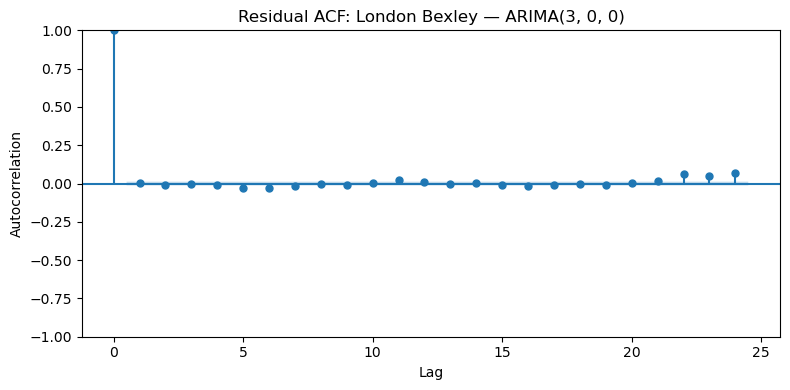

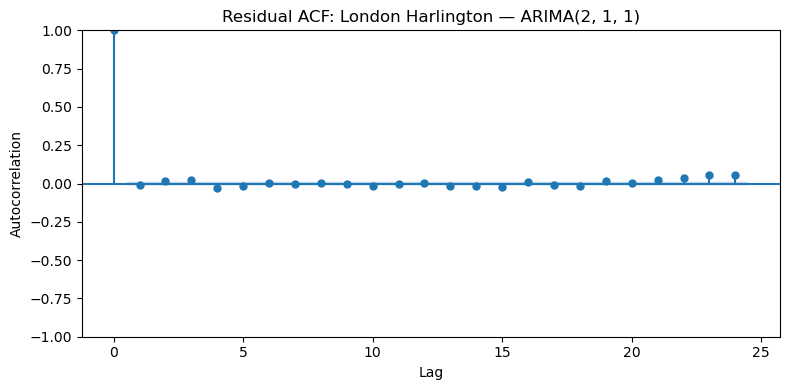

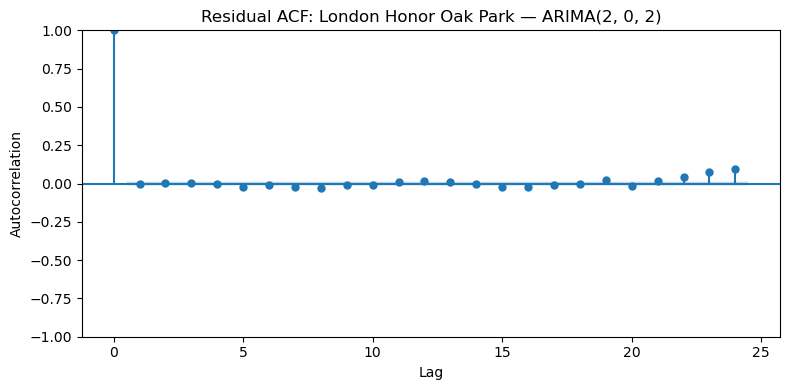

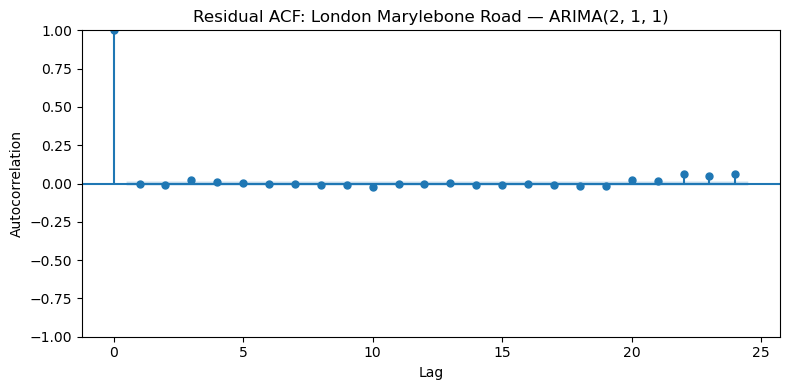

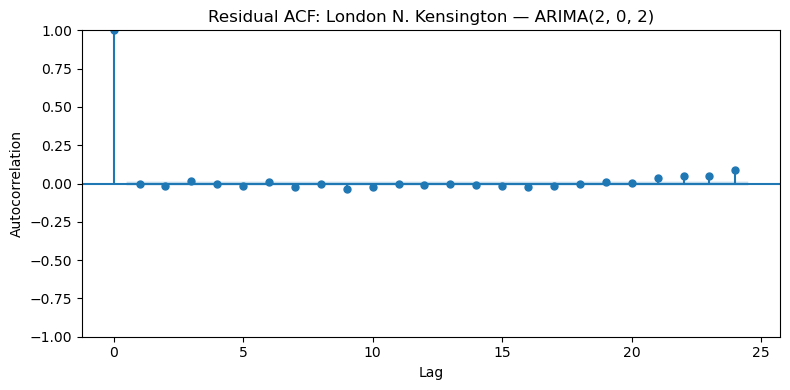

In [17]:
# ============================================================
# Step 13b: Plot residual ACF for selected ARIMA models
# ============================================================

for station_name, result in best_arima_models.items():

    residuals = pd.Series(result.resid).replace([np.inf, -np.inf], np.nan).dropna()

    if len(residuals) <= 30:
        continue

    selected_order = best_arima_orders_df.loc[
        best_arima_orders_df["Station"] == station_name,
        "OrderLabel"
    ].iloc[0]

    fig, ax = plt.subplots(figsize=(8, 4))
    plot_acf(residuals, lags=24, ax=ax)
    ax.set_title(f"Residual ACF: {station_name} — {selected_order}")
    ax.set_xlabel("Lag")
    ax.set_ylabel("Autocorrelation")
    plt.tight_layout()
    plt.show()

### Interpretation note: ARIMA residual diagnostics

The selected Kalman-ARIMA models produced residuals with near-zero mean, indicating limited average bias. However, the Ljung-Box test p-values were close to zero, suggesting that some residual autocorrelation remained after model fitting.

This does not invalidate the Kalman-ARIMA baseline. Instead, it shows that ARIMA did not fully capture all temporal structure in the noisy hourly PM2.5 series. Therefore, Kalman-ARIMA is interpreted as an interpretable statistical baseline rather than a complete model of PM2.5 dynamics.

This residual behaviour also motivates the later comparison with machine-learning and deep-learning models, which may capture nonlinear, spatial and meteorological patterns not fully represented by the univariate ARIMA structure.

## Step 14: Kalman-ARIMA imputation using the train-fitted state-space model

This step applies the selected station-level Kalman-ARIMA models to the masked Validation and Test series.

The model parameters are learned from the Train split only. The fitted model is then applied to each masked Validation/Test series using `apply(..., refit=False)`, which means the ARIMA parameters are not re-estimated on Validation or Test data.

This is important because the task is retrospective imputation, not future forecasting. Therefore, `.forecast()` is not used. Instead, missing values in `PM25_model_input` are estimated using the state-space/Kalman prediction or smoothing mechanism.

Important leakage rules:

- `PM25_original` is not used as model input.
- Artificially masked values remain hidden as `NaN` in `PM25_model_input`.
- Validation and Test are not used to refit ARIMA parameters.
- Evaluation is performed only after imputation, using `PM25_original` as ground truth.

In [18]:
# ============================================================
# Step 14: Kalman-ARIMA imputation using apply(refit=False)
# ============================================================

def get_state_space_prediction_series(applied_result, series):
    """
    Extract in-sample state-space predictions from an applied ARIMA model.

    The preferred option is smoothed predictions, because this is a retrospective
    imputation task. If the installed statsmodels version does not support
    smoothed information_set, the function falls back to standard in-sample
    predictions.

    Parameters
    ----------
    applied_result : statsmodels result object
        Result object after applying the train-fitted ARIMA model to a new series.
    series : pandas.Series
        Masked PM2.5 series used as endog.

    Returns
    -------
    pred_series : pandas.Series
        Prediction/imputation series aligned to the input datetime index.
    method_used : str
        Description of which prediction method was used.
    """

    # Preferred for retrospective imputation if available.
    try:
        pred_result = applied_result.get_prediction(
            start=series.index[0],
            end=series.index[-1],
            information_set="smoothed"
        )
        pred_mean = pred_result.predicted_mean
        method_used = "smoothed_get_prediction"

    except Exception:
        # Fallback for older statsmodels versions.
        try:
            pred_mean = applied_result.predict(
                start=series.index[0],
                end=series.index[-1],
                information_set="smoothed"
            )
            method_used = "smoothed_predict"

        except Exception:
            # Final fallback: standard in-sample prediction.
            pred_result = applied_result.get_prediction(
                start=series.index[0],
                end=series.index[-1]
            )
            pred_mean = pred_result.predicted_mean
            method_used = "standard_get_prediction"

    pred_series = pd.Series(
        np.asarray(pred_mean, dtype=float),
        index=series.index
    )

    return pred_series, method_used


def add_kalman_arima_predictions(df, best_models):
    """
    Add Kalman-ARIMA imputation predictions for Validation and Test.

    The selected ARIMA model for each station is fitted on Train only.
    It is then applied to Validation/Test using refit=False.

    This avoids re-estimating ARIMA parameters on Validation/Test data.
    """

    output_df = df.copy()
    output_df["pred_kalman_arima"] = np.nan

    application_logs = []

    eval_splits = ["Validation", "Test"]

    for (split_name, station_name), group in output_df.loc[
        output_df["Split"].isin(eval_splits)
    ].groupby(["Split", "Station"]):

        group_sorted = group.sort_values("Datetime").copy()

        series = (
            group_sorted
            .set_index("Datetime")["PM25_model_input"]
            .astype(float)
        )

        try:
            series = series.asfreq("h")
        except Exception:
            pass

        assert station_name in best_models, f"No selected ARIMA model found for {station_name}"

        train_fitted_result = best_models[station_name]

        try:
            applied_result = train_fitted_result.apply(
                endog=series,
                refit=False
            )

            pred_series, method_used = get_state_space_prediction_series(
                applied_result=applied_result,
                series=series
            )

            # Map predictions back to the original dataframe rows.
            prediction_values = group_sorted["Datetime"].map(pred_series)

            output_df.loc[
                group_sorted.index,
                "pred_kalman_arima"
            ] = prediction_values.to_numpy()

            application_logs.append({
                "Split": split_name,
                "Station": station_name,
                "N_rows": len(group_sorted),
                "N_missing_input": int(series.isna().sum()),
                "N_predictions_created": int(prediction_values.notna().sum()),
                "PredictionMethod": method_used,
                "Status": "success"
            })

        except Exception as e:
            application_logs.append({
                "Split": split_name,
                "Station": station_name,
                "N_rows": len(group_sorted),
                "N_missing_input": int(series.isna().sum()),
                "N_predictions_created": 0,
                "PredictionMethod": None,
                "Status": f"failed: {type(e).__name__}: {str(e)}"
            })

    application_logs_df = pd.DataFrame(application_logs)

    return output_df, application_logs_df

## Step 15: Evaluate Kalman-ARIMA across all masking scenarios

This step applies the train-fitted Kalman-ARIMA models to all five masking scenarios.

Evaluation is performed only at artificially masked rows, using the same metric functions as the previous statistical baselines.

In [19]:
# ============================================================
# Step 15: Run Kalman-ARIMA across all masking scenarios
# ============================================================

kalman_arima_results = []
kalman_arima_results_by_split = []
kalman_arima_results_by_split_station = []
kalman_arima_prediction_tables = []
kalman_arima_application_logs = []

for scenario_name in scenario_order:

    print(f"Processing Kalman-ARIMA for scenario: {scenario_name}")

    scenario_df = load_masked_scenario(scenario_name)

    start_time = perf_counter()

    arima_df, application_log_df = add_kalman_arima_predictions(
        df=scenario_df,
        best_models=best_arima_models
    )

    runtime_seconds = perf_counter() - start_time

    application_log_df["Scenario"] = scenario_name
    kalman_arima_application_logs.append(application_log_df)

    # Sanity check: artificial targets must still be hidden in PM25_model_input.
    artificial_mask = arima_df["is_artificial_masked"] == True

    assert arima_df.loc[artificial_mask, "PM25_model_input"].isna().all(), (
        f"Leakage risk: some artificially masked PM25_model_input values are not NaN "
        f"for scenario {scenario_name}."
    )

    # Overall evaluation.
    arima_metrics = evaluate_predictions(
        df=arima_df,
        prediction_col="pred_kalman_arima",
        scenario_name=scenario_name,
        model_name="Kalman-ARIMA"
    )

    arima_metrics["Runtime_seconds"] = runtime_seconds
    kalman_arima_results.append(arima_metrics)

    # Evaluation by split.
    kalman_arima_results_by_split.extend(
        evaluate_predictions_by_group(
            df=arima_df,
            prediction_col="pred_kalman_arima",
            scenario_name=scenario_name,
            model_name="Kalman-ARIMA",
            group_cols=["Split"]
        )
    )

    # Evaluation by split and station.
    kalman_arima_results_by_split_station.extend(
        evaluate_predictions_by_group(
            df=arima_df,
            prediction_col="pred_kalman_arima",
            scenario_name=scenario_name,
            model_name="Kalman-ARIMA",
            group_cols=["Split", "Station"]
        )
    )

    # Save target-level predictions.
    arima_targets = arima_df.loc[
        artificial_mask,
        [
            "MaskingScenario",
            "Datetime",
            "Split",
            "Station",
            "PM25_original",
            "PM25_model_input",
            "pred_kalman_arima"
        ]
    ].copy()

    arima_targets["Model"] = "Kalman-ARIMA"
    arima_targets = arima_targets.rename(
        columns={"pred_kalman_arima": "Prediction"}
    )

    kalman_arima_prediction_tables.append(arima_targets)


kalman_arima_results_df = pd.DataFrame(kalman_arima_results)
kalman_arima_results_by_split_df = pd.DataFrame(kalman_arima_results_by_split)
kalman_arima_results_by_split_station_df = pd.DataFrame(kalman_arima_results_by_split_station)
kalman_arima_predictions_df = pd.concat(kalman_arima_prediction_tables, ignore_index=True)
kalman_arima_application_logs_df = pd.concat(kalman_arima_application_logs, ignore_index=True)

print("Kalman-ARIMA overall results:")
display(
    kalman_arima_results_df.assign(
        MAE=kalman_arima_results_df["MAE"].round(4),
        RMSE=kalman_arima_results_df["RMSE"].round(4),
        R2=kalman_arima_results_df["R2"].round(4),
        MedianAE=kalman_arima_results_df["MedianAE"].round(4),
        Runtime_seconds=kalman_arima_results_df["Runtime_seconds"].round(4)
    )
)

print("Kalman-ARIMA application logs:")
display(kalman_arima_application_logs_df)

print("Kalman-ARIMA predictions shape:", kalman_arima_predictions_df.shape)
display(kalman_arima_predictions_df.head())

Processing Kalman-ARIMA for scenario: random10_point
Processing Kalman-ARIMA for scenario: random30_point
Processing Kalman-ARIMA for scenario: random50_point
Processing Kalman-ARIMA for scenario: block24_10percent
Processing Kalman-ARIMA for scenario: block72_10percent
Kalman-ARIMA overall results:


,Scenario,Model,N_targets,N_evaluated,N_missing_predictions,MAE,RMSE,R2,MedianAE,Runtime_seconds
0,random10_point,Kalman-ARIMA,8650,8650,0,0.9622,2.1539,0.9185,0.4139,0.8002
1,random30_point,Kalman-ARIMA,25951,25951,0,1.0714,2.0940,0.9218,0.4887,1.1538
2,random50_point,Kalman-ARIMA,43250,43250,0,1.2411,2.2908,0.9069,0.6071,1.1985
3,block24_10percent,Kalman-ARIMA,8784,8784,0,2.6773,4.2748,0.6359,1.6780,0.8104
4,block72_10percent,Kalman-ARIMA,9144,9144,0,3.8459,6.0557,0.2873,2.7963,0.8338


Kalman-ARIMA application logs:


,Split,Station,N_rows,N_missing_input,N_predictions_created,PredictionMethod,Status,Scenario
0,Test,London Bexley,8760,993,8760,smoothed_get_prediction,success,random10_point
1,Test,London Harlington,8760,905,8760,smoothed_get_prediction,success,random10_point
2,Test,London Honor Oak Park,8760,975,8760,smoothed_get_prediction,success,random10_point
3,Test,London Marylebone Road,8760,1174,8760,smoothed_get_prediction,success,random10_point
4,Test,London N. Kensington,8760,890,8760,smoothed_get_prediction,success,random10_point
5,Validation,London Bexley,8784,889,8784,smoothed_get_prediction,success,random10_point
6,Validation,London Harlington,8784,904,8784,smoothed_get_prediction,success,random10_point
7,Validation,London Honor Oak Park,8784,910,8784,smoothed_get_prediction,success,random10_point
8,Validation,London Marylebone Road,8784,1321,8784,smoothed_get_prediction,success,random10_point
9,Validation,London N. Kensington,8784,908,8784,smoothed_get_prediction,success,random10_point


Kalman-ARIMA predictions shape: (95779, 8)


,MaskingScenario,Datetime,Split,Station,PM25_original,PM25_model_input,Prediction,Model
0,random10_point,2024-01-01 03:00:00,Validation,London Bexley,4.245,NaN,3.249228,Kalman-ARIMA
1,random10_point,2024-01-01 04:00:00,Validation,London Bexley,4.057,NaN,3.432082,Kalman-ARIMA
2,random10_point,2024-01-01 09:00:00,Validation,London Bexley,8.113,NaN,7.167575,Kalman-ARIMA
3,random10_point,2024-01-01 10:00:00,Validation,London Bexley,8.208,NaN,7.554074,Kalman-ARIMA
4,random10_point,2024-01-01 12:00:00,Validation,London Bexley,7.264,NaN,7.281743,Kalman-ARIMA


## Step 16: Save Kalman-ARIMA results

This step saves Kalman-ARIMA metrics, grouped metrics, application logs and target-level predictions.

In [20]:
# ============================================================
# Step 16: Save Kalman-ARIMA results
# ============================================================

kalman_metrics_path = RESULTS_DIR / "kalman_arima_metrics.csv"
kalman_metrics_by_split_path = RESULTS_DIR / "kalman_arima_metrics_by_split.csv"
kalman_metrics_by_split_station_path = RESULTS_DIR / "kalman_arima_metrics_by_split_station.csv"
kalman_predictions_path = RESULTS_DIR / "kalman_arima_predictions.csv"
kalman_application_logs_path = RESULTS_DIR / "kalman_arima_application_logs.csv"

kalman_arima_results_df.to_csv(kalman_metrics_path, index=False)
kalman_arima_results_by_split_df.to_csv(kalman_metrics_by_split_path, index=False)
kalman_arima_results_by_split_station_df.to_csv(kalman_metrics_by_split_station_path, index=False)
kalman_arima_predictions_df.to_csv(kalman_predictions_path, index=False)
kalman_arima_application_logs_df.to_csv(kalman_application_logs_path, index=False)

print("Saved Kalman-ARIMA metrics:")
print(kalman_metrics_path)

print("\nSaved Kalman-ARIMA metrics by split:")
print(kalman_metrics_by_split_path)

print("\nSaved Kalman-ARIMA metrics by split and station:")
print(kalman_metrics_by_split_station_path)

print("\nSaved Kalman-ARIMA predictions:")
print(kalman_predictions_path)

print("\nSaved Kalman-ARIMA application logs:")
print(kalman_application_logs_path)

Saved Kalman-ARIMA metrics:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\kalman_arima_metrics.csv

Saved Kalman-ARIMA metrics by split:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\kalman_arima_metrics_by_split.csv

Saved Kalman-ARIMA metrics by split and station:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\kalman_arima_metrics_by_split_station.csv

Saved Kalman-ARIMA predictions:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\kalman_arima_predictions.csv

Saved Kalman-ARIMA application logs:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\kalman_arima_application_logs.csv


In [21]:
# ============================================================
# Step 17: Combine all statistical baseline metrics
# ============================================================

all_statistical_metrics_df = pd.concat(
    [
        baseline_results_df,
        kalman_arima_results_df
    ],
    ignore_index=True
)

all_statistical_metrics_path = RESULTS_DIR / "all_statistical_baseline_metrics.csv"
all_statistical_metrics_df.to_csv(all_statistical_metrics_path, index=False)

display(
    all_statistical_metrics_df
    .sort_values(["Scenario", "MAE"])
    .assign(
        MAE=lambda x: x["MAE"].round(4),
        RMSE=lambda x: x["RMSE"].round(4),
        R2=lambda x: x["R2"].round(4),
        MedianAE=lambda x: x["MedianAE"].round(4),
        Runtime_seconds=lambda x: x["Runtime_seconds"].round(4)
    )
)

print("Saved combined statistical baseline metrics:")
print(all_statistical_metrics_path)

,Scenario,Model,N_targets,N_evaluated,N_missing_predictions,MAE,RMSE,R2,MedianAE,Runtime_seconds
13,block24_10percent,Kalman-ARIMA,8784,8784,0,2.6773,4.2748,0.6359,1.6780,0.8104
7,block24_10percent,Linear interpolation,8784,8784,0,2.8173,4.5458,0.5883,1.7200,0.1650
6,block24_10percent,Station train mean,8784,8784,0,4.7982,6.9753,0.0306,3.7780,0.0823
9,block72_10percent,Linear interpolation,9144,9144,0,3.6597,5.7591,0.3554,2.3569,0.1494
14,block72_10percent,Kalman-ARIMA,9144,9144,0,3.8459,6.0557,0.2873,2.7963,0.8338
8,block72_10percent,Station train mean,9144,9144,0,4.6932,6.9959,0.0488,3.8348,0.0780
10,random10_point,Kalman-ARIMA,8650,8650,0,0.9622,2.1539,0.9185,0.4139,0.8002
1,random10_point,Linear interpolation,8650,8650,0,0.9992,2.2138,0.9139,0.4392,0.1545
0,random10_point,Station train mean,8650,8650,0,5.0366,7.4284,0.0301,4.0145,0.0722
11,random30_point,Kalman-ARIMA,25951,25951,0,1.0714,2.0940,0.9218,0.4887,1.1538


Saved combined statistical baseline metrics:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\all_statistical_baseline_metrics.csv


In [29]:
# ============================================================
# Step 17b: Combine grouped statistical baseline metrics
# ============================================================

all_statistical_metrics_by_split_df = pd.concat(
    [
        baseline_results_by_split_df,
        kalman_arima_results_by_split_df
    ],
    ignore_index=True
)

all_statistical_metrics_by_split_station_df = pd.concat(
    [
        baseline_results_by_split_station_df,
        kalman_arima_results_by_split_station_df
    ],
    ignore_index=True
)

all_statistical_metrics_by_split_path = (
    RESULTS_DIR / "all_statistical_baseline_metrics_by_split.csv"
)

all_statistical_metrics_by_split_station_path = (
    RESULTS_DIR / "all_statistical_baseline_metrics_by_split_station.csv"
)

all_statistical_metrics_by_split_df.to_csv(
    all_statistical_metrics_by_split_path,
    index=False
)

all_statistical_metrics_by_split_station_df.to_csv(
    all_statistical_metrics_by_split_station_path,
    index=False
)

print("Saved combined statistical baseline metrics by split:")
print(all_statistical_metrics_by_split_path)

print("\nSaved combined statistical baseline metrics by split and station:")
print(all_statistical_metrics_by_split_station_path)

print("\nCombined by-split metrics:")
display(
    all_statistical_metrics_by_split_df
    .sort_values(["Scenario", "Split", "MAE"])
    .assign(
        MAE=lambda x: x["MAE"].round(4),
        RMSE=lambda x: x["RMSE"].round(4),
        R2=lambda x: x["R2"].round(4),
        MedianAE=lambda x: x["MedianAE"].round(4)
    )
)

Saved combined statistical baseline metrics by split:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\all_statistical_baseline_metrics_by_split.csv

Saved combined statistical baseline metrics by split and station:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\all_statistical_baseline_metrics_by_split_station.csv

Combined by-split metrics:


,Scenario,Model,N_evaluated,MAE,RMSE,R2,MedianAE,Split
26,block24_10percent,Kalman-ARIMA,4392,2.7969,4.4872,0.6970,1.7117,Test
14,block24_10percent,Linear interpolation,4392,2.9087,4.7722,0.6573,1.6985,Test
12,block24_10percent,Station train mean,4392,5.3770,8.0878,0.0156,3.8630,Test
27,block24_10percent,Kalman-ARIMA,4392,2.5577,4.0512,0.4948,1.6408,Validation
15,block24_10percent,Linear interpolation,4392,2.7259,4.3076,0.4288,1.7338,Validation
13,block24_10percent,Station train mean,4392,4.2193,5.6478,0.0181,3.7199,Validation
18,block72_10percent,Linear interpolation,4536,3.9881,6.3280,0.4013,2.6256,Test
28,block72_10percent,Kalman-ARIMA,4536,4.2636,6.8816,0.2920,3.0263,Test
16,block72_10percent,Station train mean,4536,5.0157,7.9175,0.0627,3.8560,Test
19,block72_10percent,Linear interpolation,4608,3.3365,5.1380,0.2416,2.1186,Validation


In [30]:
# ============================================================
# Step 17c: Final Test-only statistical baseline comparison
# ============================================================

final_test_metrics_df = (
    all_statistical_metrics_by_split_df
    .loc[all_statistical_metrics_by_split_df["Split"] == "Test"]
    .sort_values(["Scenario", "MAE"])
    .copy()
)

scenario_order = [
    "random10_point", "random30_point", "random50_point",
    "block24_10percent", "block72_10percent"
]

final_test_metrics_df["Scenario"] = pd.Categorical(
    final_test_metrics_df["Scenario"], categories=scenario_order, ordered=True
)
final_test_metrics_df = final_test_metrics_df.sort_values(["Scenario", "MAE"])

final_test_metrics_display = final_test_metrics_df[
    ["Scenario", "Model", "N_evaluated", "MAE", "RMSE", "R2", "MedianAE"]
].copy()

print("Final statistical baseline comparison on the Test split:")
display(
    final_test_metrics_display.assign(
        MAE=final_test_metrics_display["MAE"].round(4),
        RMSE=final_test_metrics_display["RMSE"].round(4),
        R2=final_test_metrics_display["R2"].round(4),
        MedianAE=final_test_metrics_display["MedianAE"].round(4)
    )
)

final_test_metrics_path = RESULTS_DIR / "final_test_statistical_baseline_comparison.csv"
final_test_metrics_display.to_csv(final_test_metrics_path, index=False)

print("Saved final Test-only statistical baseline comparison:")
print(final_test_metrics_path)

Final statistical baseline comparison on the Test split:


,Scenario,Model,N_evaluated,MAE,RMSE,R2,MedianAE
20,random10_point,Kalman-ARIMA,4318,0.9398,1.7372,0.9574,0.4205
2,random10_point,Linear interpolation,4318,0.9819,1.7918,0.9546,0.4715
0,random10_point,Station train mean,4318,5.4330,8.3373,0.0177,4.0510
22,random30_point,Kalman-ARIMA,12954,1.0567,1.9163,0.9487,0.4939
6,random30_point,Linear interpolation,12954,1.0920,1.9699,0.9458,0.5033
4,random30_point,Station train mean,12954,5.4684,8.4058,0.0138,4.0610
24,random50_point,Kalman-ARIMA,21590,1.2341,2.1910,0.9343,0.6184
10,random50_point,Linear interpolation,21590,1.2691,2.2451,0.9310,0.6380
8,random50_point,Station train mean,21590,5.5068,8.4909,0.0127,4.0610
26,block24_10percent,Kalman-ARIMA,4392,2.7969,4.4872,0.6970,1.7117


Saved final Test-only statistical baseline comparison:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\final_test_statistical_baseline_comparison.csv


In [31]:
# ============================================================
# Step 17d: Station-level Test statistical baseline performance
# ============================================================

station_test_metrics_df = (
    all_statistical_metrics_by_split_station_df
    .loc[all_statistical_metrics_by_split_station_df["Split"] == "Test"]
    .sort_values(["Scenario", "Model", "Station"])
    .copy()
)

station_test_metrics_display = station_test_metrics_df[
    ["Scenario", "Model", "Station", "N_evaluated", "MAE", "RMSE", "R2", "MedianAE"]
].copy()

print("Station-level statistical baseline performance on the Test split:")
display(
    station_test_metrics_display.assign(
        MAE=station_test_metrics_display["MAE"].round(4),
        RMSE=station_test_metrics_display["RMSE"].round(4),
        R2=station_test_metrics_display["R2"].round(4),
        MedianAE=station_test_metrics_display["MedianAE"].round(4)
    )
)

station_test_metrics_path = RESULTS_DIR / "station_level_test_statistical_baseline_metrics.csv"
station_test_metrics_display.to_csv(station_test_metrics_path, index=False)

print("Saved station-level Test statistical baseline metrics:")
print(station_test_metrics_path)

Station-level statistical baseline performance on the Test split:


,Scenario,Model,Station,N_evaluated,MAE,RMSE,R2,MedianAE
130,block24_10percent,Kalman-ARIMA,London Bexley,864,3.1323,4.9206,0.6891,1.8966
131,block24_10percent,Kalman-ARIMA,London Harlington,888,2.7108,5.3047,0.6771,1.2601
132,block24_10percent,Kalman-ARIMA,London Honor Oak Park,888,2.5012,3.8771,0.6997,1.6344
133,block24_10percent,Kalman-ARIMA,London Marylebone Road,864,3.4011,4.7212,0.7012,2.5900
134,block24_10percent,Kalman-ARIMA,London N. Kensington,888,2.2645,3.3423,0.6557,1.4593
...,...,...,...,...,...,...,...,...
40,random50_point,Station train mean,London Bexley,4315,6.0944,9.5446,-0.0072,4.3440
41,random50_point,Station train mean,London Harlington,4364,5.2743,8.4699,-0.0117,3.6253
42,random50_point,Station train mean,London Honor Oak Park,4325,4.8940,7.4837,-0.0001,3.7315
43,random50_point,Station train mean,London Marylebone Road,4214,5.9882,8.6815,-0.0000,4.8560


Saved station-level Test statistical baseline metrics:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\station_level_test_statistical_baseline_metrics.csv


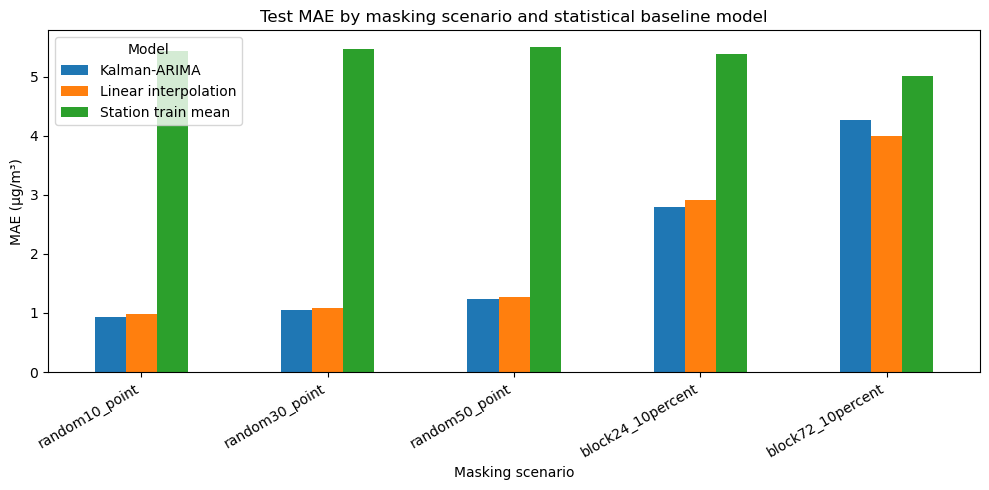

Saved Test MAE comparison plot:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\test_mae_by_scenario_statistical_baselines.png


In [32]:
# ============================================================
# Step 17e: Visual comparison of Test MAE by scenario and model
# ============================================================

plot_df = (
    final_test_metrics_df
    .pivot(index="Scenario", columns="Model", values="MAE")
    .reindex(scenario_order)
)


ax = plot_df.plot(kind="bar", figsize=(10, 5))

ax.set_title("Test MAE by masking scenario and statistical baseline model")
ax.set_xlabel("Masking scenario")
ax.set_ylabel("MAE (µg/m³)")
ax.legend(title="Model")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

mae_plot_path = RESULTS_DIR / "test_mae_by_scenario_statistical_baselines.png"
plt.savefig(mae_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved Test MAE comparison plot:")
print(mae_plot_path)

The pooled Validation+Test metrics are retained as an overall diagnostic summary only. They are not used as the primary final benchmark. Final cross-model comparison will use Test-split metrics from `all_statistical_baseline_metrics_by_split.csv`, with Validation results reported separately.

## Step 18: Save statistical model artefacts

This step saves the reusable statistical model artefacts from Notebook 06.

The station mean baseline does not have a fitted model object, but its station-level training means are saved.

Linear interpolation is deterministic and has no trained model object, so its configuration is saved for reproducibility.

Kalman-ARIMA has fitted station-level state-space model objects, so these are saved separately. This allows the selected ARIMA models to be reloaded later without repeating the full AIC search.

In [33]:
# ============================================================
# Step 18: Save statistical model artefacts
# ============================================================

import json
import re

print("Statistical model artefact directory:")
print(STAT_MODELS_DIR)

def safe_filename(text):
    """
    Convert station/model names into safe file names.
    """
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9]+", "_", text)
    text = text.strip("_")
    return text


# ------------------------------------------------------------
# 1. Save station train mean artefact
# ------------------------------------------------------------

station_train_mean_artifact = (
    arima_reference_df
    .loc[arima_reference_df["Split"] == "Train"]
    .groupby("Station", as_index=False)["PM25_model_input"]
    .mean()
    .rename(columns={"PM25_model_input": "StationTrainMean_PM25"})
)

station_train_mean_path = STAT_MODELS_DIR / "station_train_mean_values.csv"
station_train_mean_artifact.to_csv(station_train_mean_path, index=False)

print("\nSaved station train mean values:")
print(station_train_mean_path)

display(station_train_mean_artifact)


# ------------------------------------------------------------
# 2. Save linear interpolation configuration
# ------------------------------------------------------------

linear_interpolation_config = {
    "Model": "Linear interpolation",
    "Grouping": ["Split", "Station"],
    "InputColumn": "PM25_model_input",
    "TimeColumn": "Datetime",
    "InterpolationMethod": "time",
    "LimitDirection": "both",
    "Description": (
        "Linear interpolation is applied separately within each Split-Station "
        "time series using PM25_model_input. It has no fitted model object."
    )
}

linear_interpolation_config_path = STAT_MODELS_DIR / "linear_interpolation_config.json"

with open(linear_interpolation_config_path, "w") as f:
    json.dump(linear_interpolation_config, f, indent=4)

print("\nSaved linear interpolation configuration:")
print(linear_interpolation_config_path)


# ------------------------------------------------------------
# 3. Save Kalman-ARIMA fitted model objects
# ------------------------------------------------------------

arima_model_manifest_records = []

for _, row in best_arima_orders_df.iterrows():

    station_name = row["Station"]
    order_label = row["OrderLabel"]

    assert station_name in best_arima_models, f"Missing fitted ARIMA model for {station_name}"

    fitted_result = best_arima_models[station_name]

    station_safe = safe_filename(station_name)
    order_safe = safe_filename(order_label)

    model_filename = f"kalman_arima_{station_safe}_{order_safe}.pkl"
    model_path = STAT_MODELS_DIR / model_filename

    # Save the fitted statsmodels result object.
    fitted_result.save(str(model_path))

    arima_model_manifest_records.append({
        "Station": station_name,
        "OrderLabel": order_label,
        "Trend": row["Trend"],
        "AIC": row["AIC"],
        "BIC": row["BIC"],
        "LogLikelihood": row["LogLikelihood"],
        "Converged": row["Converged"],
        "ModelObjectPath": str(model_path)
    })

arima_model_manifest_df = pd.DataFrame(arima_model_manifest_records)

arima_model_manifest_path = STAT_MODELS_DIR / "kalman_arima_model_manifest.csv"
arima_model_manifest_df.to_csv(arima_model_manifest_path, index=False)

print("\nSaved Kalman-ARIMA fitted model objects.")
print("\nSaved Kalman-ARIMA model manifest:")
print(arima_model_manifest_path)

display(arima_model_manifest_df)


# ------------------------------------------------------------
# 4. Save overall statistical model configuration
# ------------------------------------------------------------

statistical_model_config = {
    "Notebook": "06_statistical_baseline_imputation.ipynb",
    "Models": {
        "Station train mean": {
            "Type": "Naive statistical baseline",
            "Input": "Train split PM25_model_input",
            "Artefact": str(station_train_mean_path)
        },
        "Linear interpolation": {
            "Type": "Deterministic time-series imputation baseline",
            "Input": "PM25_model_input",
            "Config": str(linear_interpolation_config_path)
        },
        "Kalman-ARIMA": {
            "Type": "State-space ARIMA / Kalman smoothing statistical baseline",
            "OrderSelection": "AIC-based search on Train split only",
            "CandidateOrders": [str(order) for order in candidate_orders],
            "SelectedOrders": str(best_arima_orders_path),
            "ModelManifest": str(arima_model_manifest_path)
        }
    },
    "ImportantLeakageRule": (
        "PM25_original is used only for evaluation. Model inputs and imputation "
        "methods use PM25_model_input."
    )
}

statistical_model_config_path = STAT_MODELS_DIR / "statistical_baseline_model_config.json"

with open(statistical_model_config_path, "w") as f:
    json.dump(statistical_model_config, f, indent=4)

print("\nSaved overall statistical model configuration:")
print(statistical_model_config_path)

Statistical model artefact directory:
C:\Users\Msi\Desktop\DISSERTATION\Codes\models\statistical_baselines

Saved station train mean values:
C:\Users\Msi\Desktop\DISSERTATION\Codes\models\statistical_baselines\station_train_mean_values.csv


,Station,StationTrainMean_PM25
0,London Bexley,8.966961
1,London Harlington,7.594330
2,London Honor Oak Park,7.976453
3,London Marylebone Road,11.144036
4,London N. Kensington,8.390986



Saved linear interpolation configuration:
C:\Users\Msi\Desktop\DISSERTATION\Codes\models\statistical_baselines\linear_interpolation_config.json

Saved Kalman-ARIMA fitted model objects.

Saved Kalman-ARIMA model manifest:
C:\Users\Msi\Desktop\DISSERTATION\Codes\models\statistical_baselines\kalman_arima_model_manifest.csv


,Station,OrderLabel,Trend,AIC,BIC,LogLikelihood,Converged,ModelObjectPath
0,London Bexley,"ARIMA(3, 0, 0)",c,121782.246725,121823.128972,-60886.123363,True,C:\Users\Msi\Desktop\DISSERTATION\Codes\models...
1,London Harlington,"ARIMA(2, 1, 1)",n,104657.213411,104689.919208,-52324.606705,True,C:\Users\Msi\Desktop\DISSERTATION\Codes\models...
2,London Honor Oak Park,"ARIMA(2, 0, 2)",c,103896.732266,103945.790962,-51942.366133,True,C:\Users\Msi\Desktop\DISSERTATION\Codes\models...
3,London Marylebone Road,"ARIMA(2, 1, 1)",n,120754.823519,120787.529316,-60373.411759,True,C:\Users\Msi\Desktop\DISSERTATION\Codes\models...
4,London N. Kensington,"ARIMA(2, 0, 2)",c,102882.289884,102931.348580,-51435.144942,True,C:\Users\Msi\Desktop\DISSERTATION\Codes\models...



Saved overall statistical model configuration:
C:\Users\Msi\Desktop\DISSERTATION\Codes\models\statistical_baselines\statistical_baseline_model_config.json


## Step 19: Error-vs-position diagnostic inside 72-hour masked blocks

This diagnostic checks whether imputation error changes systematically within the 72-hour block-masking scenario.

For retrospective, bilateral imputation methods, errors are expected to be lower near the observed anchors at the block edges and higher around the middle of the block. A clearly increasing one-sided pattern would suggest forward-only behaviour, while near-zero errors would require investigation for potential target leakage.

This is treated as a diagnostic consistency check rather than a formal proof of no leakage. The primary leakage safeguards remain that `PM25_original` is used only for evaluation and that artificial target rows have `PM25_model_input = NaN` before prediction.

Saved error-by-position plot: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\block72_error_by_position_in_block.png


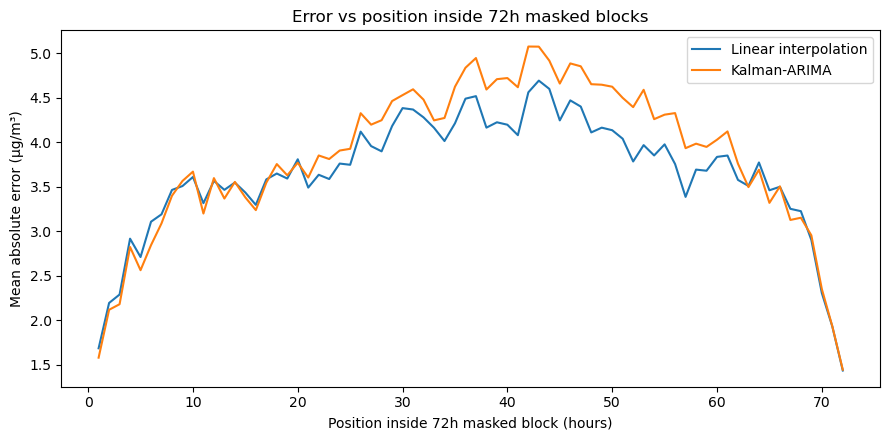

Saved error-by-position profile: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\block72_error_by_position_in_block.csv


,Edge_MAE,MidBlock_MAE,Mid_to_Edge_Ratio
Linear interpolation,1.813,4.273,2.357
Kalman-ARIMA,1.770,4.643,2.623


Diagnostic passed: mid-block error is higher than edge error for both temporal models.


In [34]:
# ============================================================
# Step 19: Error-vs-position diagnostic inside 72h masked blocks
# ============================================================

scenario_df = load_masked_scenario("block72_10percent")

# Recompute both temporal models' predictions on this scenario.
interp_df = add_linear_interpolation_predictions(scenario_df)
arima_df, _ = add_kalman_arima_predictions(scenario_df, best_arima_models)

# Merge ARIMA predictions into the interpolation frame.
interp_df["pred_kalman_arima"] = arima_df["pred_kalman_arima"]

# Safety checks before analysing errors.
assert interp_df.loc[interp_df["is_artificial_masked"], "PM25_model_input"].isna().all(), (
    "Leakage risk: some artificial target PM25_model_input values are not NaN."
)

prediction_cols = ["pred_linear_interpolation", "pred_kalman_arima"]
assert interp_df.loc[interp_df["is_artificial_masked"], prediction_cols].notna().all().all(), (
    "Some artificial targets do not have predictions."
)

# Keep artificially masked rows only and identify each contiguous masked block.
targets = (
    interp_df.loc[interp_df["is_artificial_masked"]]
    .sort_values(["Split", "Station", "Datetime"])
    .copy()
)

# A new block starts whenever the hourly gap to the previous masked row exceeds 1 hour.
targets["block_id"] = (
    targets.groupby(["Split", "Station"])["Datetime"]
    .transform(lambda s: (s.diff() != pd.Timedelta(hours=1)).cumsum())
)

# Position 1..72 inside each block.
targets["pos_in_block"] = (
    targets.groupby(["Split", "Station", "block_id"]).cumcount() + 1
)

# Safety: every block should be exactly 72 hours, matching the Notebook 05 design.
block_lengths = targets.groupby(["Split", "Station", "block_id"]).size()
assert (block_lengths == 72).all(), "Found a masked run that is not exactly 72h."

# Mean absolute error by position for both temporal models.
for col in prediction_cols:
    targets[f"abs_err_{col}"] = (targets["PM25_original"] - targets[col]).abs()

pos_profile = (
    targets.groupby("pos_in_block")[
        ["abs_err_pred_linear_interpolation", "abs_err_pred_kalman_arima"]
    ]
    .mean()
    .rename(columns={
        "abs_err_pred_linear_interpolation": "Linear interpolation",
        "abs_err_pred_kalman_arima": "Kalman-ARIMA",
    })
)

fig, ax = plt.subplots(figsize=(9, 4.5))
pos_profile.plot(ax=ax)
ax.set_xlabel("Position inside 72h masked block (hours)")
ax.set_ylabel("Mean absolute error (µg/m³)")
ax.set_title("Error vs position inside 72h masked blocks")
plt.tight_layout()

error_position_plot_path = RESULTS_DIR / "block72_error_by_position_in_block.png"
plt.savefig(error_position_plot_path, dpi=300, bbox_inches="tight")
print("Saved error-by-position plot:", error_position_plot_path)

plt.show()

pos_profile_path = RESULTS_DIR / "block72_error_by_position_in_block.csv"
pos_profile.to_csv(pos_profile_path)
print("Saved error-by-position profile:", pos_profile_path)

# Quantitative edge-vs-middle diagnostic.
edge = pos_profile.iloc[[0, 1, 70, 71]].mean()
middle = pos_profile.iloc[30:42].mean()
ratio = middle / edge

summary_df = pd.DataFrame({
    "Edge_MAE": edge,
    "MidBlock_MAE": middle,
    "Mid_to_Edge_Ratio": ratio
})

display(summary_df.round(3))

if (middle > edge).all():
    print("Diagnostic passed: mid-block error is higher than edge error for both temporal models.")
else:
    print(
        "Diagnostic warning: mid-block error is not higher than edge error for at least one model. "
        "This is not automatic evidence of leakage, but the pattern should be inspected."
    )

### Step 20: Example 72-hour masked block imputation plot

This step visualises one challenging 72-hour masked block from the Test split. It compares the original PM2.5 series with the values imputed by linear interpolation and Kalman-ARIMA. The aim is to show the qualitative behaviour of the statistical methods during long contiguous gaps, beyond what can be seen from aggregate error metrics alone.

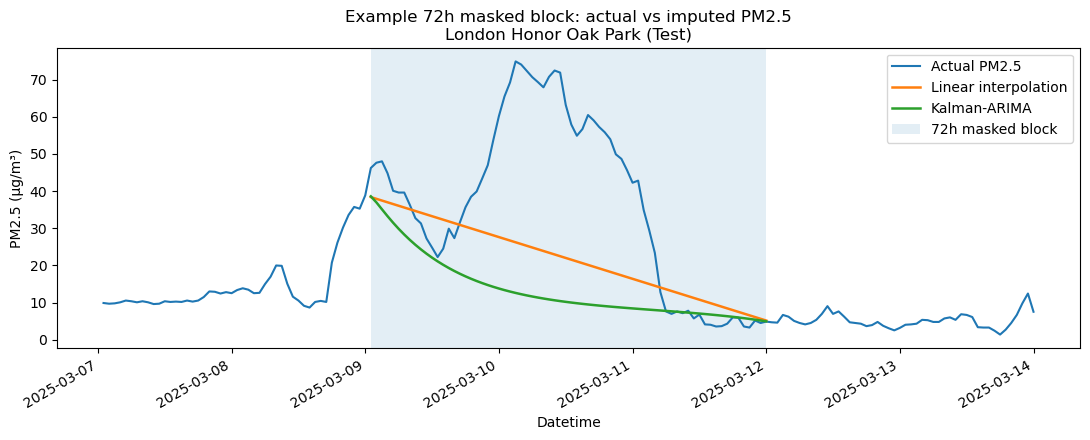

Saved example 72h block imputation plot:
C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines\example_72h_block_actual_vs_imputed.png


In [35]:
# ============================================================
# Step 20: Example 72h masked block — actual vs imputed values
# ============================================================

# Select a challenging Test block with high PM2.5 variability.
test_targets = targets.loc[targets["Split"] == "Test"].copy()

block_variability = (
    test_targets
    .groupby(["Split", "Station", "block_id"])["PM25_original"]
    .std()
    .sort_values(ascending=False)
)

example_split, example_station, example_block = block_variability.index[0]

example_block_df = test_targets.loc[
    (test_targets["Split"] == example_split) &
    (test_targets["Station"] == example_station) &
    (test_targets["block_id"] == example_block)
].copy()

t0 = example_block_df["Datetime"].min()
t1 = example_block_df["Datetime"].max()

# Add 48 hours of context before and after the masked block.
context_df = interp_df.loc[
    (interp_df["Split"] == example_split) &
    (interp_df["Station"] == example_station) &
    (interp_df["Datetime"].between(
        t0 - pd.Timedelta(hours=48),
        t1 + pd.Timedelta(hours=48)
    ))
].sort_values("Datetime").copy()

block_mask = context_df["Datetime"].between(t0, t1) & context_df["is_artificial_masked"]

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(
    context_df["Datetime"],
    context_df["PM25_original"],
    linewidth=1.5,
    label="Actual PM2.5"
)

ax.plot(
    context_df.loc[block_mask, "Datetime"],
    context_df.loc[block_mask, "pred_linear_interpolation"],
    linewidth=1.8,
    label="Linear interpolation"
)

ax.plot(
    context_df.loc[block_mask, "Datetime"],
    context_df.loc[block_mask, "pred_kalman_arima"],
    linewidth=1.8,
    label="Kalman-ARIMA"
)

ax.axvspan(t0, t1, alpha=0.12, label="72h masked block")

ax.set_title(
    f"Example 72h masked block: actual vs imputed PM2.5\n"
    f"{example_station} ({example_split})"
)
ax.set_xlabel("Datetime")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

case_plot_path = RESULTS_DIR / "example_72h_block_actual_vs_imputed.png"
plt.savefig(case_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved example 72h block imputation plot:")
print(case_plot_path)